# Predictive Memory Leak Detection — 04: Leak-warning evaluation

This notebook evaluates whether your saved forecasts support useful warnings about ongoing injected leaks. **It reuses your verified Colab results; it does not retrain the LSTM. CPU is sufficient.**

## What you need to do
1. Upload this notebook as a **separate notebook** in Colab.
2. Run the cells in order. At the upload prompt, select **`review2_warning_inputs.zip`**, approximately 31 MB. It already contains your verified preprocessed data and LSTM/baseline forecasts.
3. Let the evaluation finish. Inspect the point metrics, event outcomes and warning timeline. There is no requirement that LSTM outperform the simpler rules.
4. Confirm the final check says **`all_checks_passed: True`**.
5. Save the downloaded `review2_warning_results.zip` as **`review2_warning_results_colab.zip`** in the project's `data/packages` folder. Keep the executed notebook too.

## What is a warning?
At each origin, estimate memory growth from the most recent 12 observations. For an assisted rule, also calculate growth from the current value to the saved future forecast. Both must exceed the selected growth threshold for **three consecutive samples**. Compare:

- **Trend only:** recent growth alone.
- **ARIMA + trend:** recent growth and ARIMA forecast growth.
- **LSTM + trend:** recent growth and LSTM forecast growth.
- **Always off:** a control that produces no warnings.

All growth values use percentage points of total RAM per minute. On Antarex, 12 observations span 55 seconds, the forecast horizon is 60 seconds, and three consecutive qualifying observations span 10 seconds. These are fixed pilot settings, not tuned optima.

## How this is scored
Thresholds are selected by the highest **validation** F1 and frozen before scoring test warnings. A point is positive if an injected leak is active at the **warning origin**, not at the forecast target. No whole-event point adjustment is used. [Kim et al. (AAAI 2022)](https://doi.org/10.1609/aaai.v36i7.20680) motivates avoiding inflated scores from that adjustment.

- **Precision:** of warning-active samples, how many coincide with a recorded leak?
- **Recall:** of leak-active samples, how many receive a warning?
- **F1:** the precision/recall balance, derived directly from TP, FP and FN.
- **Event recall:** how many fully observed injected leaks contain a new alarm start?
- **Detection delay:** seconds from exact injection onset to the first new alarm during that leak, reported only for detected events; missed events remain listed.
- **False alarms:** false-positive samples and new alarms outside recorded leaks. These negatives include other injected faults.

An alarm already active before a leak begins does not earn a new event detection. Incomplete events are listed as excluded. Blank/NaN ratios mean **undefined**, not successful detection. For example, always-off precision is undefined while its recall and F1 are zero when leaks exist.

This measures recognition after an injection starts. The pilot contains no memory-exhaustion event, so it does not establish warning lead time before exhaustion. Westermo has no confirmed leak labels; its transferred alarms are descriptive only.

Review 1 reference [13], [Jindal et al. (2021)](https://arxiv.org/abs/2106.08938), grounds the use of memory trends as a comparator. This simple conjunction is our pilot rule, not a reimplementation of Precog. No Mann–Kendall significance result is claimed.


## 1. Prepare the CPU runtime
Only numerical, table and plotting libraries are needed. No GPU or model-training packages are required.

In [1]:
from pathlib import Path
import importlib.util
import subprocess
import sys

missing=[name for name in ['numpy','pandas','matplotlib','PIL'] if importlib.util.find_spec(name) is None]
if missing:
    subprocess.check_call([sys.executable,'-m','pip','install','--quiet',*[('pillow' if x=='PIL' else x) for x in missing]])
print('Dependencies ready. This stage uses saved forecasts and does not retrain models.')


Dependencies ready. This stage uses saved forecasts and does not retrain models.


## 2. Upload the warning input ZIP
Select **`review2_warning_inputs.zip`**. The raw-data ZIP and model-training input ZIP are not the inputs for this stage. Download the result before Colab's temporary runtime storage disappears.

In [2]:
try:
    IN_COLAB=importlib.util.find_spec('google.colab') is not None
except ModuleNotFoundError:
    IN_COLAB=False
if IN_COLAB:
    WORK=Path('/content/memory_leak_warnings')
    INPUT_PACKAGE=Path('/content/review2_warning_inputs.zip')
    if not INPUT_PACKAGE.exists():
        from google.colab import files
        uploaded=files.upload()
        if 'review2_warning_inputs.zip' not in uploaded:
            raise FileNotFoundError('Select review2_warning_inputs.zip, then rerun this cell.')
        INPUT_PACKAGE.write_bytes(uploaded['review2_warning_inputs.zip'])
        del uploaded
else:
    WORK=Path.cwd().resolve()
    if not (WORK/'data/packages/review2_warning_inputs.zip').exists() and (WORK.parent/'data/packages/review2_warning_inputs.zip').exists():
        WORK=WORK.parent
    INPUT_PACKAGE=WORK/'data/packages/review2_warning_inputs.zip'
SOURCE=WORK/'data/warning_inputs'
OUTPUT=WORK/'results/warnings'
RESULT_PACKAGE=WORK/'data/packages/review2_warning_results.zip'
print('Input:',INPUT_PACKAGE)
print('Result folder:',OUTPUT)


Input: C:\dhruv\VIT\Sem-5\OS\Research_Project\data\packages\review2_warning_inputs.zip
Result folder: C:\dhruv\VIT\Sem-5\OS\Research_Project\results\warnings


## 3. Load the complete evaluation code
No other source files need uploading. It includes safe ZIP verification, past-only score calculation, validation threshold selection, test metrics, event outcomes and plots. The project includes focused tests for timing, gap handling, undefined ratios and event boundaries.

In [3]:
"""Fixed, causal warning evaluation using the verified Colab forecasts."""
from datetime import datetime, timezone
import hashlib
import io
import json
from pathlib import Path
import platform
import time
import zipfile

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

PROTOCOL_VERSION = 'review2-warning-v1'
PREP_SHA256 = '287ffaa139819f78f493e540e527c56ac0c240477034c76fa8b258b94d5e6bb2'
FORECAST_SHA256 = '42cd2d51f29a06d2f6a0912a8b787d343898b11ac3ac55c4b397264743c1a7bf'
SETTINGS = {'trend_observations': 12, 'consecutive_samples': 3,
            'threshold_grid_pp_per_minute': [0.01, 0.025, 0.05, 0.1, 0.2, 0.4, 0.8, 1.6, 3.2],
            'selection': 'validation point F1; fewer FP; higher threshold',
            'event_detection': 'new alarm start within fully covered injected event',
            'point_adjustment': False}
METHODS = ['trend_only', 'arima_growth', 'lstm_growth', 'always_off']
LABELS = {'trend_only': 'Trend only', 'arima_growth': 'ARIMA + trend',
          'lstm_growth': 'LSTM + trend', 'always_off': 'Always off'}
COLORS = {'trend_only': '#00897B', 'arima_growth': '#7850B2', 'lstm_growth': '#D23C50', 'always_off': '#808080'}


def read_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))


def dump_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, allow_nan=False), encoding='utf-8')


def file_sha256(path):
    with Path(path).open('rb') as f:
        return hashlib.file_digest(f, 'sha256').hexdigest()


def unpack_inputs(package, destination):
    destination = Path(destination).resolve()
    expected = {'review2_preprocessed_colab.zip': (PREP_SHA256, 'prepared'),
                'review2_lstm_results_colab.zip': (FORECAST_SHA256, 'forecasts')}
    with zipfile.ZipFile(package) as outer:
        names = outer.namelist()
        assert len(names) == 3 and set(names) == set(expected) | {'MANIFEST.json'}
        manifest = json.loads(outer.read('MANIFEST.json'))
        assert manifest['protocol_version'] == PROTOCOL_VERSION
        assert {f['entry'] for f in manifest['files']} == set(expected)
        for name, (digest, subdir) in expected.items():
            content = outer.read(name)
            assert hashlib.sha256(content).hexdigest() == digest, 'Unexpected source ZIP: ' + name
            item = next(f for f in manifest['files'] if f['entry'] == name)
            assert item['sha256'] == digest and item['bytes'] == len(content)
            with zipfile.ZipFile(io.BytesIO(content)) as archive:
                inner = json.loads(archive.read('MANIFEST.json'))
                listed = [f['entry'] for f in inner['files']]
                assert len(listed) == len(set(listed))
                assert len(archive.namelist()) == len(listed) + 1
                assert set(archive.namelist()) == set(listed) | {'MANIFEST.json'}
                for item in inner['files']:
                    target = (destination / subdir / item['entry']).resolve()
                    assert target.is_relative_to(destination / subdir), 'Unsafe archive entry'
                    data = archive.read(item['entry'])
                    assert len(data) == item['bytes'] and hashlib.sha256(data).hexdigest() == item['sha256']
                    target.parent.mkdir(parents=True, exist_ok=True)
                    target.write_bytes(data)
    forecast = read_json(destination / 'forecasts/experiment_summary.json')
    assert forecast['input_provenance']['prepared_package_sha256'] == PREP_SHA256
    assert read_json(destination / 'forecasts/result_integrity_checks.json')['all_checks_passed']
    receipt = {'combined_package_sha256': file_sha256(package), 'prepared_package_sha256': PREP_SHA256,
               'forecast_package_sha256': FORECAST_SHA256, 'protocol_sha256': manifest['protocol_sha256']}
    return destination, receipt


def warning_scores(y, origins, forecast_arima, forecast_lstm, cadence, horizon, history=12):
    """Only past/current observations and forecasts are read; no labels or future truth."""
    origins = np.asarray(origins, dtype=np.int64)
    indices = origins[:, None] - np.arange(history - 1, -1, -1)
    assert indices.min() >= 0 and origins.max() < len(y)
    past = np.asarray(y, dtype=np.float64)[indices]
    x = (np.arange(history) - (history - 1) / 2) * cadence / 60
    slope = (past @ x) / np.dot(x, x) * 100
    current = np.asarray(y, dtype=np.float64)[origins]
    arima_growth = (np.asarray(forecast_arima) - current) * 100 / (horizon / 60)
    lstm_growth = (np.asarray(forecast_lstm) - current) * 100 / (horizon / 60)
    assert np.isfinite(past).all() and np.isfinite(arima_growth).all() and np.isfinite(lstm_growth).all()
    return {'observed_growth_pp_per_minute': slope,
            'arima_forecast_growth_pp_per_minute': arima_growth,
            'lstm_forecast_growth_pp_per_minute': lstm_growth,
            'trend_only_score': slope, 'arima_growth_score': np.minimum(slope, arima_growth),
            'lstm_growth_score': np.minimum(slope, lstm_growth)}


def load_frame(source, name, split):
    source = Path(source)
    info = read_json(source / 'prepared' / name / 'summary.json')
    with np.load(source / 'prepared' / name / 'model_arrays.npz', allow_pickle=False) as z:
        arrays = {k: z[k] for k in ['target_memory_pressure', 'timestamps', 'valid', 'split_code', 'leak_active', 'label_known']}
    pred = pd.read_csv(source / 'forecasts' / name / (split + '_predictions.csv.gz'))
    windows = pd.read_csv(source / 'prepared' / name / 'forecast_windows.csv.gz')
    windows = windows[windows['split'].eq(split)]
    index_columns = ['origin_index', 'target_index', 'origin_timestamp', 'target_timestamp']
    np.testing.assert_array_equal(pred[index_columns], windows[index_columns])
    o, t = (pred[c].to_numpy(dtype=np.int64) for c in ['origin_index', 'target_index'])
    h = windows['history_start_index'].to_numpy(dtype=np.int64)
    assert (np.diff(o) > 0).all()
    invalid = np.r_[0, np.cumsum(~arrays['valid'])]
    assert (invalid[t + 1] - invalid[h] == 0).all()
    assert (arrays['split_code'][h] == arrays['split_code'][t]).all()
    assert (arrays['split_code'][o] == {'validation': 1, 'test': 2}[split]).all()
    assert (arrays['timestamps'][t] - arrays['timestamps'][o] == info['forecast_horizon_seconds']).all()
    assert (arrays['timestamps'][o] - arrays['timestamps'][h] == (info['history_steps'] - 1) * info['cadence_seconds']).all()
    np.testing.assert_allclose(pred['actual'], arrays['target_memory_pressure'][t], rtol=0, atol=1e-15)
    np.testing.assert_allclose(pred['leak_active_at_origin'], arrays['leak_active'][o], equal_nan=True)
    scores = warning_scores(arrays['target_memory_pressure'], o, pred['arima'], pred['lstm'],
                            info['cadence_seconds'], info['forecast_horizon_seconds'], SETTINGS['trend_observations'])
    frame = pred[index_columns].copy()
    frame['memory_pressure_at_origin'] = arrays['target_memory_pressure'][o].astype(np.float64)
    frame['arima_forecast'] = pred['arima']
    frame['lstm_forecast'] = pred['lstm']
    for key, value in scores.items():
        frame[key] = value
    frame['leak_active'] = arrays['leak_active'][o].astype(np.float64)
    frame['label_known'] = arrays['label_known'][o]
    if name.startswith('antarex'):
        assert frame['label_known'].all() and frame['leak_active'].isin([0, 1]).all()
        episodes = pd.read_csv(source / 'prepared' / name / 'leak_episodes.csv')
        derived = np.zeros(len(frame), dtype=bool)
        for e in episodes.itertuples(index=False):
            derived |= (frame['origin_timestamp'] >= e.start) & (frame['origin_timestamp'] < e.end)
        np.testing.assert_array_equal(derived, frame['leak_active'].astype(bool))
    else:
        assert not frame['label_known'].any() and frame['leak_active'].isna().all()
    return frame, info


def warning_state(scores, timestamps, threshold, cadence, consecutive=3):
    times = np.asarray(timestamps, dtype=np.int64)
    assert len(times) and (np.diff(times) > 0).all()
    if threshold is None:
        return np.zeros(len(times), dtype=bool)
    scores = np.asarray(scores, dtype=np.float64)
    assert len(scores) == len(times) and np.isfinite(scores).all() and threshold > 0 and consecutive >= 1
    active = np.zeros(len(times), dtype=bool)
    run = 0
    for i, (value, timestamp) in enumerate(zip(scores, times)):
        if i == 0 or timestamp - times[i - 1] != cadence:
            run = 0
        run = run + 1 if value >= threshold else 0
        active[i] = run >= consecutive
    return active


def alarm_starts(active, timestamps, cadence):
    active = np.asarray(active, dtype=bool)
    times = np.asarray(timestamps, dtype=np.int64)
    continuation = np.r_[False, active[:-1] & (np.diff(times) == cadence)]
    return active & ~continuation


def ratio(numerator, denominator):
    return float(numerator / denominator) if denominator else None


def point_metrics(labels, active, timestamps, cadence):
    labels = np.asarray(labels)
    active = np.asarray(active, dtype=bool)
    assert len(labels) == len(active) and np.isin(labels, [0, 1]).all()
    truth = labels.astype(bool)
    tp, fp, tn, fn = (int(mask.sum()) for mask in [truth & active, ~truth & active, ~truth & ~active, truth & ~active])
    starts = alarm_starts(active, timestamps, cadence)
    false_starts = int((starts & ~truth).sum())
    non_leak_hours = (fp + tn) * cadence / 3600
    return {'n': len(truth), 'tp': tp, 'fp': fp, 'tn': tn, 'fn': fn,
            'precision': ratio(tp, tp + fp), 'recall': ratio(tp, tp + fn), 'f1': ratio(2 * tp, 2 * tp + fp + fn),
            'warning_fraction': float(active.mean()), 'false_positive_fraction': ratio(fp, fp + tn),
            'observed_hours': len(truth) * cadence / 3600, 'non_leak_observed_hours': non_leak_hours,
            'false_positive_exposure_minutes': fp * cadence / 60, 'alarm_starts': int(starts.sum()),
            'false_alarm_starts': false_starts, 'false_alarm_starts_per_non_leak_hour': ratio(false_starts, non_leak_hours)}


def select_thresholds(validation, cadence):
    assert validation['label_known'].all()
    candidates, selected = [], {}
    times, truth = validation['origin_timestamp'], validation['leak_active']
    for method in METHODS:
        choices = [None] if method == 'always_off' else SETTINGS['threshold_grid_pp_per_minute'] + [None]
        rows = []
        for threshold in choices:
            score = np.zeros(len(validation)) if method == 'always_off' else validation[method + '_score']
            active = warning_state(score, times, threshold, cadence, SETTINGS['consecutive_samples'])
            row = {'method': method, 'threshold_pp_per_minute': threshold, **point_metrics(truth, active, times, cadence)}
            rows.append(row)
            candidates.append(row)
        best = min(rows, key=lambda r: (-(r['f1'] if r['f1'] is not None else -1), r['fp'],
                                        -(r['threshold_pp_per_minute'] if r['threshold_pp_per_minute'] is not None else float('inf'))))
        selected[method] = {'threshold_pp_per_minute': best['threshold_pp_per_minute'],
                            'validation_f1': best['f1'], 'validation_fp': best['fp']}
    return selected, pd.DataFrame(candidates)


def apply_thresholds(frame, selected, cadence):
    frame = frame.copy()
    for method in METHODS:
        score = np.zeros(len(frame)) if method == 'always_off' else frame[method + '_score']
        active = warning_state(score, frame['origin_timestamp'], selected[method]['threshold_pp_per_minute'],
                               cadence, SETTINGS['consecutive_samples'])
        frame[method + '_warning'] = active
        frame[method + '_alarm_start'] = alarm_starts(active, frame['origin_timestamp'], cadence)
    return frame


def event_metrics(episodes, timestamps, active, cadence):
    times = np.asarray(timestamps, dtype=np.int64)
    starts = alarm_starts(active, times, cadence)
    rows = []
    for episode in episodes.itertuples(index=False):
        if episode.end <= times[0] or episode.start > times[-1]:
            continue
        inside = np.flatnonzero((times >= episode.start) & (times < episode.end))
        reason = ''
        if not len(inside) or episode.start < times[0] or episode.end > times[-1] + cadence or inside[0] == 0:
            reason = 'boundary_or_no_origin_coverage'
        else:
            covered = times[inside[0] - 1:inside[-1] + 1]
            if (np.diff(covered) != cadence).any() or times[inside[0]] - episode.start >= cadence or episode.end - times[inside[-1]] > cadence:
                reason = 'coverage_gap'
        eligible = not reason
        hits = times[inside[starts[inside]]] if len(inside) else np.array([], dtype=np.int64)
        detected = bool(eligible and len(hits))
        rows.append({'episode_id': int(episode.episode_id), 'start': int(episode.start), 'end': int(episode.end),
                     'low_intensity': bool(episode.low_intensity), 'eligible': eligible, 'exclusion_reason': reason,
                     'detected': detected if eligible else None,
                     'first_alarm_start': int(hits[0]) if detected else None,
                     'delay_seconds': float(hits[0] - episode.start) if detected else None})
    columns = ['episode_id', 'start', 'end', 'low_intensity', 'eligible', 'exclusion_reason', 'detected', 'first_alarm_start', 'delay_seconds']
    table = pd.DataFrame(rows, columns=columns)
    eligible = [r for r in rows if r['eligible']]
    delays = [r['delay_seconds'] for r in eligible if r['detected']]
    return {'intersecting_events': len(rows), 'eligible_events': len(eligible), 'excluded_events': len(rows) - len(eligible),
            'detected_events': len(delays), 'missed_events': len(eligible) - len(delays),
            'event_recall': ratio(len(delays), len(eligible)),
            'median_delay_seconds_detected_only': float(np.median(delays)) if delays else None,
            'p90_delay_seconds_detected_only': float(np.quantile(delays, .9)) if delays else None}, table


def score_antarex(frame, episodes, cadence, split):
    points, events, tables = [], [], []
    for method in METHODS:
        active = frame[method + '_warning'].to_numpy(dtype=bool)
        points.append({'dataset': 'antarex_mono', 'split': split, 'method': method,
                       **point_metrics(frame['leak_active'], active, frame['origin_timestamp'], cadence)})
        score, table = event_metrics(episodes, frame['origin_timestamp'], active, cadence)
        events.append({'dataset': 'antarex_mono', 'split': split, 'method': method, **score})
        table.insert(0, 'method', method)
        table.insert(0, 'split', split)
        tables.append(table)
    return pd.DataFrame(points), pd.DataFrame(events), pd.concat(tables, ignore_index=True)


def describe_unlabeled(frame, name, cadence):
    assert not frame['label_known'].any() and frame['leak_active'].isna().all()
    rows = []
    for method in METHODS:
        active = frame[method + '_warning'].to_numpy(dtype=bool)
        count = int(alarm_starts(active, frame['origin_timestamp'], cadence).sum())
        hours = len(frame) * cadence / 3600
        rows.append({'dataset': name, 'split': 'test', 'method': method, 'eligible_origins': len(frame),
                     'observed_hours': hours, 'warning_origins': int(active.sum()), 'warning_fraction': float(active.mean()),
                     'alarm_starts': count, 'alarm_starts_per_observed_hour': count / hours, 'leak_labels_available': False})
    return pd.DataFrame(rows)


def save_figure(fig, path):
    for suffix in ['.png', '.pdf']:
        fig.savefig(Path(path).with_suffix(suffix), dpi=160)
    plt.close(fig)


def make_figures(output, test_frame, episodes, point_table, event_table):
    output = Path(output)
    first = int(test_frame['origin_timestamp'].iloc[0])
    frame = test_frame[test_frame['origin_timestamp'].between(first, first + 1800)].copy()
    frame.to_csv(output / 'antarex_first_test_30min.csv', index=False)
    x = (frame['origin_timestamp'] - first) / 60
    fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, layout='constrained', gridspec_kw={'height_ratios': [2, 1.5]})
    axes[0].plot(x, frame['memory_pressure_at_origin'] * 100, color='#172B4D', lw=1.7)
    axes[0].set(ylabel='Memory pressure (% of total RAM)', title='Antarex | recorded memory and causal warning activity')
    for i, method in enumerate(METHODS[:3]):
        axes[1].fill_between(x, i, i + .65 * frame[method + '_warning'].astype(float), step='post', color=COLORS[method], alpha=.9)
    for ax in axes:
        for j, e in enumerate(episodes[(episodes['end'] > first) & (episodes['start'] < first + 1800)].itertuples(index=False)):
            ax.axvspan((max(first, e.start) - first) / 60, (min(first + 1800, e.end) - first) / 60,
                       color='#E57373', alpha=.15, label='Injected leak active' if j == 0 else None)
        ax.grid(alpha=.2)
        ax.spines[['top', 'right']].set_visible(False)
    axes[0].legend(loc='upper right')
    axes[1].set(yticks=np.arange(3) + .325, yticklabels=[LABELS[m] for m in METHODS[:3]],
                xlabel=f'Warning origin: minutes from {first}', ylim=(-.15, 2.9))
    fig.supxlabel('Shading is recorded injection; colored bands are warnings available at that time. No pre-exhaustion claim.', fontsize=9)
    save_figure(fig, output / 'antarex_warning_timeline')

    point_test = point_table[point_table['split'].eq('test')].set_index('method')
    event_test = event_table[event_table['split'].eq('test')].set_index('method')
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.7), layout='constrained')
    for i, method in enumerate(METHODS[:3]):
        vals = point_test.loc[method, ['precision', 'recall', 'f1']].to_numpy(dtype=float)
        bars = axes[0].bar(np.arange(3) + (i - 1) * .23, np.nan_to_num(vals), .23, color=COLORS[method], label=LABELS[method])
        axes[0].bar_label(bars, labels=['undefined' if np.isnan(v) else f'{v:.3f}' for v in vals], fontsize=8)
    axes[0].set(xticks=np.arange(3), xticklabels=['Precision', 'Recall', 'F1'], ylim=(0, 1.18), title='Unadjusted origin-level warning scores')
    axes[0].legend(fontsize=8, loc='upper right')
    vals = event_test.loc[METHODS[:3], 'event_recall'].to_numpy(dtype=float)
    bars = axes[1].bar(np.arange(3), np.nan_to_num(vals), color=[COLORS[m] for m in METHODS[:3]])
    axes[1].bar_label(bars, labels=[f'{int(event_test.loc[m, "detected_events"])}/{int(event_test.loc[m, "eligible_events"])} events' for m in METHODS[:3]], fontsize=9)
    axes[1].set(xticks=np.arange(3), xticklabels=[LABELS[m] for m in METHODS[:3]], ylim=(0, 1.18), title='Event recall: new alarm within leak interval')
    for ax in axes:
        ax.set_ylabel('Fraction')
        ax.spines[['top', 'right']].set_visible(False)
        ax.grid(axis='y', alpha=.2)
    fig.supxlabel('Antarex test | thresholds chosen on validation | always-off control retained in the tables', fontsize=9)
    save_figure(fig, output / 'antarex_warning_comparison')

    fig, axes = plt.subplots(1, 3, figsize=(11, 3.8), layout='constrained')
    for ax, method in zip(axes, METHODS[:3]):
        row = point_test.loc[method]
        matrix = np.array([[row['tn'], row['fp']], [row['fn'], row['tp']]], dtype=int)
        ax.imshow(matrix, cmap='Blues', vmin=0, vmax=max(1, matrix.max()))
        for (i, j), count in np.ndenumerate(matrix):
            ax.text(j, i, f'{count:,}', ha='center', va='center', color='white' if count > matrix.max() / 2 else '#172B4D')
        ax.set(xticks=[0, 1], xticklabels=['No warning', 'Warning'], yticks=[0, 1],
               yticklabels=['No leak', 'Leak active'], title=LABELS[method], xlabel='Predicted state', ylabel='Recorded state')
    fig.suptitle('Antarex test | confusion counts at warning origins')
    save_figure(fig, output / 'antarex_confusion_matrices')


def run_experiment(source, output, provenance):
    source, output = Path(source), Path(output)
    output.mkdir(parents=True, exist_ok=True)
    started = time.perf_counter()
    validation, info = load_frame(source, 'antarex_mono', 'validation')
    selected, candidates = select_thresholds(validation, info['cadence_seconds'])
    candidates.to_csv(output / 'validation_candidates.csv', index=False)
    freeze = {'protocol_version': PROTOCOL_VERSION, 'settings': SETTINGS, 'input_provenance': provenance,
              'completed_utc': datetime.now(timezone.utc).isoformat(), 'test_warning_evaluation_started': False,
              'selected': selected, 'selection_partition': 'antarex_validation',
              'validation_candidates_sha256': file_sha256(output / 'validation_candidates.csv')}
    dump_json(output / 'selection_freeze.json', freeze)
    freeze_hash = file_sha256(output / 'selection_freeze.json')
    print('Thresholds frozen using validation only:', selected, flush=True)
    episodes = pd.read_csv(source / 'prepared/antarex_mono/leak_episodes.csv')
    point_tables, event_tables, event_details = [], [], []
    for split in ['validation', 'test']:
        frame = validation if split == 'validation' else load_frame(source, 'antarex_mono', split)[0]
        frame = apply_thresholds(frame, selected, info['cadence_seconds'])
        frame.to_csv(output / ('antarex_' + split + '_warnings.csv.gz'), index=False, compression='gzip')
        p, e, detail = score_antarex(frame, episodes, info['cadence_seconds'], split)
        point_tables.append(p)
        event_tables.append(e)
        event_details.append(detail)
        if split == 'test':
            test_frame = frame
    points, events = pd.concat(point_tables, ignore_index=True), pd.concat(event_tables, ignore_index=True)
    points.to_csv(output / 'antarex_point_metrics.csv', index=False)
    events.to_csv(output / 'antarex_event_metrics.csv', index=False)
    pd.concat(event_details, ignore_index=True).to_csv(output / 'antarex_event_outcomes.csv', index=False)
    descriptions = []
    for name in ['westermo_1', 'westermo_2', 'westermo_3']:
        frame, meta = load_frame(source, name, 'test')
        frame = apply_thresholds(frame, selected, meta['cadence_seconds'])
        frame.to_csv(output / (name + '_test_warnings.csv.gz'), index=False, compression='gzip')
        descriptions.append(describe_unlabeled(frame, name, meta['cadence_seconds']))
    pd.concat(descriptions, ignore_index=True).to_csv(output / 'westermo_descriptive_alarms.csv', index=False)
    make_figures(output, test_frame, episodes, points, events)
    assert file_sha256(output / 'selection_freeze.json') == freeze_hash
    summary = {'protocol_version': PROTOCOL_VERSION, 'settings': SETTINGS, 'input_provenance': provenance,
               'completed_utc': datetime.now(timezone.utc).isoformat(), 'selection_freeze_sha256': freeze_hash,
               'runtime': {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__, 'matplotlib': matplotlib.__version__},
               'elapsed_seconds': time.perf_counter() - started,
               'timing_scope': 'offline input-table reads, warning calibration/evaluation and plots; excludes input unpacking, model inference, final verification and ZIP creation',
               'model_retraining_performed': False, 'warning_test_tuning_performed': False,
               'westermo_leak_metrics_computed': False, 'memory_exhaustion_evaluated': False,
               'paper_draft_written': False}
    dump_json(output / 'experiment_summary.json', summary)
    print(points[points['split'].eq('test')][['method', 'tp', 'fp', 'tn', 'fn', 'precision', 'recall', 'f1']].to_string(index=False), flush=True)
    print(events[events['split'].eq('test')].to_string(index=False), flush=True)
    return summary


def verify_results(source, output):
    source, output = Path(source), Path(output)
    freeze, summary = read_json(output / 'selection_freeze.json'), read_json(output / 'experiment_summary.json')
    assert summary['selection_freeze_sha256'] == file_sha256(output / 'selection_freeze.json')
    assert freeze['settings'] == SETTINGS and freeze['test_warning_evaluation_started'] is False
    assert freeze['validation_candidates_sha256'] == file_sha256(output / 'validation_candidates.csv')
    validation, meta = load_frame(source, 'antarex_mono', 'validation')
    selected, candidates = select_thresholds(validation, meta['cadence_seconds'])
    assert selected == freeze['selected']
    pd.testing.assert_frame_equal(candidates, pd.read_csv(output / 'validation_candidates.csv'), check_exact=False, rtol=1e-10, atol=1e-12)
    points, events, details, descriptions = [], [], [], []
    episodes = pd.read_csv(source / 'prepared/antarex_mono/leak_episodes.csv')
    warning_values = 0
    for name, split in [('antarex_mono', 'validation'), ('antarex_mono', 'test'),
                        ('westermo_1', 'test'), ('westermo_2', 'test'), ('westermo_3', 'test')]:
        original, info = load_frame(source, name, split)
        expected = apply_thresholds(original, selected, info['cadence_seconds'])
        prefix = 'antarex' if name == 'antarex_mono' else name
        saved = pd.read_csv(output / (prefix + '_' + split + '_warnings.csv.gz'))
        pd.testing.assert_frame_equal(expected, saved, check_exact=False, rtol=1e-10, atol=1e-12)
        warning_values += len(saved) * len(METHODS)
        # Direct confusion-count reconstruction, independent of point_metrics.
        if name == 'antarex_mono':
            truth = saved['leak_active'].astype(bool).to_numpy()
            for method in METHODS:
                active = saved[method + '_warning'].to_numpy()
                counts = np.bincount(2 * truth.astype(int) + active.astype(int), minlength=4)
                row = pd.read_csv(output / 'antarex_point_metrics.csv').query('split == @split and method == @method').iloc[0]
                np.testing.assert_array_equal(counts, row[['tn', 'fp', 'fn', 'tp']].to_numpy(dtype=int))
            p, e, d = score_antarex(saved, episodes, info['cadence_seconds'], split)
            points.append(p)
            events.append(e)
            details.append(d)
            if split == 'test':
                plotted = pd.read_csv(output / 'antarex_first_test_30min.csv')
                expected_plot = saved[saved['origin_timestamp'].between(saved['origin_timestamp'].iloc[0], saved['origin_timestamp'].iloc[0] + 1800)].reset_index(drop=True)
                pd.testing.assert_frame_equal(plotted, expected_plot, check_exact=False, rtol=1e-10, atol=1e-12)
        else:
            descriptions.append(describe_unlabeled(saved, name, info['cadence_seconds']))
    for name, tables in [('antarex_point_metrics', points), ('antarex_event_metrics', events),
                         ('antarex_event_outcomes', details), ('westermo_descriptive_alarms', descriptions)]:
        expected = pd.concat(tables, ignore_index=True)
        # Normalize CSV's representation of missing values and boolean columns.
        expected = pd.read_csv(io.StringIO(expected.to_csv(index=False)))
        pd.testing.assert_frame_equal(expected, pd.read_csv(output / (name + '.csv')), check_exact=False, rtol=1e-10, atol=1e-12)
    evidence = {'all_checks_passed': True, 'warning_decisions_recomputed': warning_values,
                'validation_selection_reproduced': True, 'test_confusion_counts_independently_reconstructed': True,
                'event_outcomes_recomputed': True, 'westermo_labels_remain_unknown': True,
                'selection_unchanged': True, 'point_adjustment_used': False}
    dump_json(output / 'result_integrity_checks.json', evidence)
    return evidence


def package_results(output, package):
    output, package = Path(output), Path(package)
    package.parent.mkdir(parents=True, exist_ok=True)
    paths = sorted(p for p in output.rglob('*') if p.is_file())
    manifest = {'stage': 'forecast-assisted warning evaluation', 'protocol_version': PROTOCOL_VERSION,
                'prepared_package_sha256': PREP_SHA256, 'forecast_package_sha256': FORECAST_SHA256,
                'files': [{'entry': p.relative_to(output).as_posix(), 'bytes': p.stat().st_size, 'sha256': file_sha256(p)} for p in paths]}
    with zipfile.ZipFile(package, 'w', compression=zipfile.ZIP_DEFLATED, compresslevel=6) as archive:
        for path in paths:
            archive.write(path, path.relative_to(output).as_posix())
        archive.writestr('MANIFEST.json', json.dumps(manifest, indent=2))
    with zipfile.ZipFile(package) as archive:
        for item in manifest['files']:
            assert hashlib.sha256(archive.read(item['entry'])).hexdigest() == item['sha256']
    receipt = {'file': package.name, 'bytes': package.stat().st_size, 'sha256': file_sha256(package), 'all_entry_hashes_verified': True}
    dump_json(package.with_suffix('.manifest.json'), receipt)
    return receipt


## 4. Verify inputs and run the fixed experiment
The candidate thresholds are 0.01, 0.025, 0.05, 0.1, 0.2, 0.4, 0.8, 1.6 and 3.2 percentage points per minute, plus a disabled candidate. Each rule gets its own validation-selected threshold. Ties use fewer false-positive samples, then the higher threshold. A saved selection record is written before test-warning evaluation.

Leave these settings unchanged after viewing test results. A weaker result for the LSTM warning is still valid evidence, even if its forecasting RMSE was better.

In [4]:
source_folder,input_receipt=unpack_inputs(INPUT_PACKAGE,SOURCE)
print('Input integrity checks passed:',input_receipt)
summary=run_experiment(source_folder,OUTPUT,input_receipt)
print('Runtime:',summary['runtime'])
print('Offline experiment elapsed seconds:',round(summary['elapsed_seconds'],2))


Input integrity checks passed: {'combined_package_sha256': '22201607ad3e0778e38dbc8ed5f688a608a1a7fb3aa37f648448527e94b8199b', 'prepared_package_sha256': '287ffaa139819f78f493e540e527c56ac0c240477034c76fa8b258b94d5e6bb2', 'forecast_package_sha256': '42cd2d51f29a06d2f6a0912a8b787d343898b11ac3ac55c4b397264743c1a7bf', 'protocol_sha256': 'e2959497c559f86cf664893719ff27d014bbc431434eeb981c7d8d309c39b662'}
Thresholds frozen using validation only: {'trend_only': {'threshold_pp_per_minute': 0.8, 'validation_f1': 0.8010204081632653, 'validation_fp': 408}, 'arima_growth': {'threshold_pp_per_minute': None, 'validation_f1': 0.0, 'validation_fp': 0}, 'lstm_growth': {'threshold_pp_per_minute': 0.4, 'validation_f1': 0.5739329268292683, 'validation_fp': 164}, 'always_off': {'threshold_pp_per_minute': None, 'validation_f1': 0.0, 'validation_fp': 0}}
      method   tp  fp    tn   fn  precision   recall       f1
  trend_only 1661 410 28689  272   0.802028 0.859286 0.829670
arima_growth    0   0 29099 193

## 5. Review selected thresholds, classification scores and event delays
Precision/recall/F1 are fractions between 0 and 1. Event delay summaries cover **detected events only**, so always read them alongside detected and missed counts. The complete per-event table is included in the output ZIP.

In [5]:
frozen=read_json(OUTPUT/'selection_freeze.json')
display(pd.DataFrame([{'method':LABELS[m],**v} for m,v in frozen['selected'].items()]))
point_results=pd.read_csv(OUTPUT/'antarex_point_metrics.csv')
event_results=pd.read_csv(OUTPUT/'antarex_event_metrics.csv')
display(point_results[point_results['split'].eq('test')][['method','tp','fp','tn','fn','precision','recall','f1','false_alarm_starts_per_non_leak_hour']])
display(event_results[event_results['split'].eq('test')][['method','eligible_events','detected_events','missed_events','excluded_events','event_recall','median_delay_seconds_detected_only','p90_delay_seconds_detected_only']])
print('NaN/blank ratios or delays mean undefined, not zero error or successful detection.')


method,threshold_pp_per_minute,validation_f1,validation_fp
Trend only,0.8,0.801020,408
ARIMA + trend,NaN,0.000000,0
LSTM + trend,0.4,0.573933,164
Always off,NaN,0.000000,0


method,tp,fp,tn,fn,precision,recall,f1,false_alarm_starts_per_non_leak_hour
trend_only,1661,410,28689,272,0.802028,0.859286,0.829670,2.127908
arima_growth,0,0,29099,1933,NaN,0.000000,0.000000,0.000000
lstm_growth,901,162,28937,1032,0.847601,0.466115,0.601469,1.039211
always_off,0,0,29099,1933,NaN,0.000000,0.000000,0.000000


method,eligible_events,detected_events,missed_events,excluded_events,event_recall,median_delay_seconds_detected_only,p90_delay_seconds_detected_only
trend_only,35,35,0,0,1.000000,30.0,56.0
arima_growth,35,0,35,0,0.000000,NaN,NaN
lstm_growth,35,34,1,0,0.971429,31.0,45.7
always_off,35,0,35,0,0.000000,NaN,NaN


NaN/blank ratios or delays mean undefined, not zero error or successful detection.


## 6. Inspect the warning timeline and confusion matrices
The timeline uses the first 30 minutes of eligible test **origins**, fixed before seeing warning performance. Red shading marks recorded injection; colored bands mark actual rule outputs. An unmarked point is not retrospectively converted into a warning just because that event was detected elsewhere.

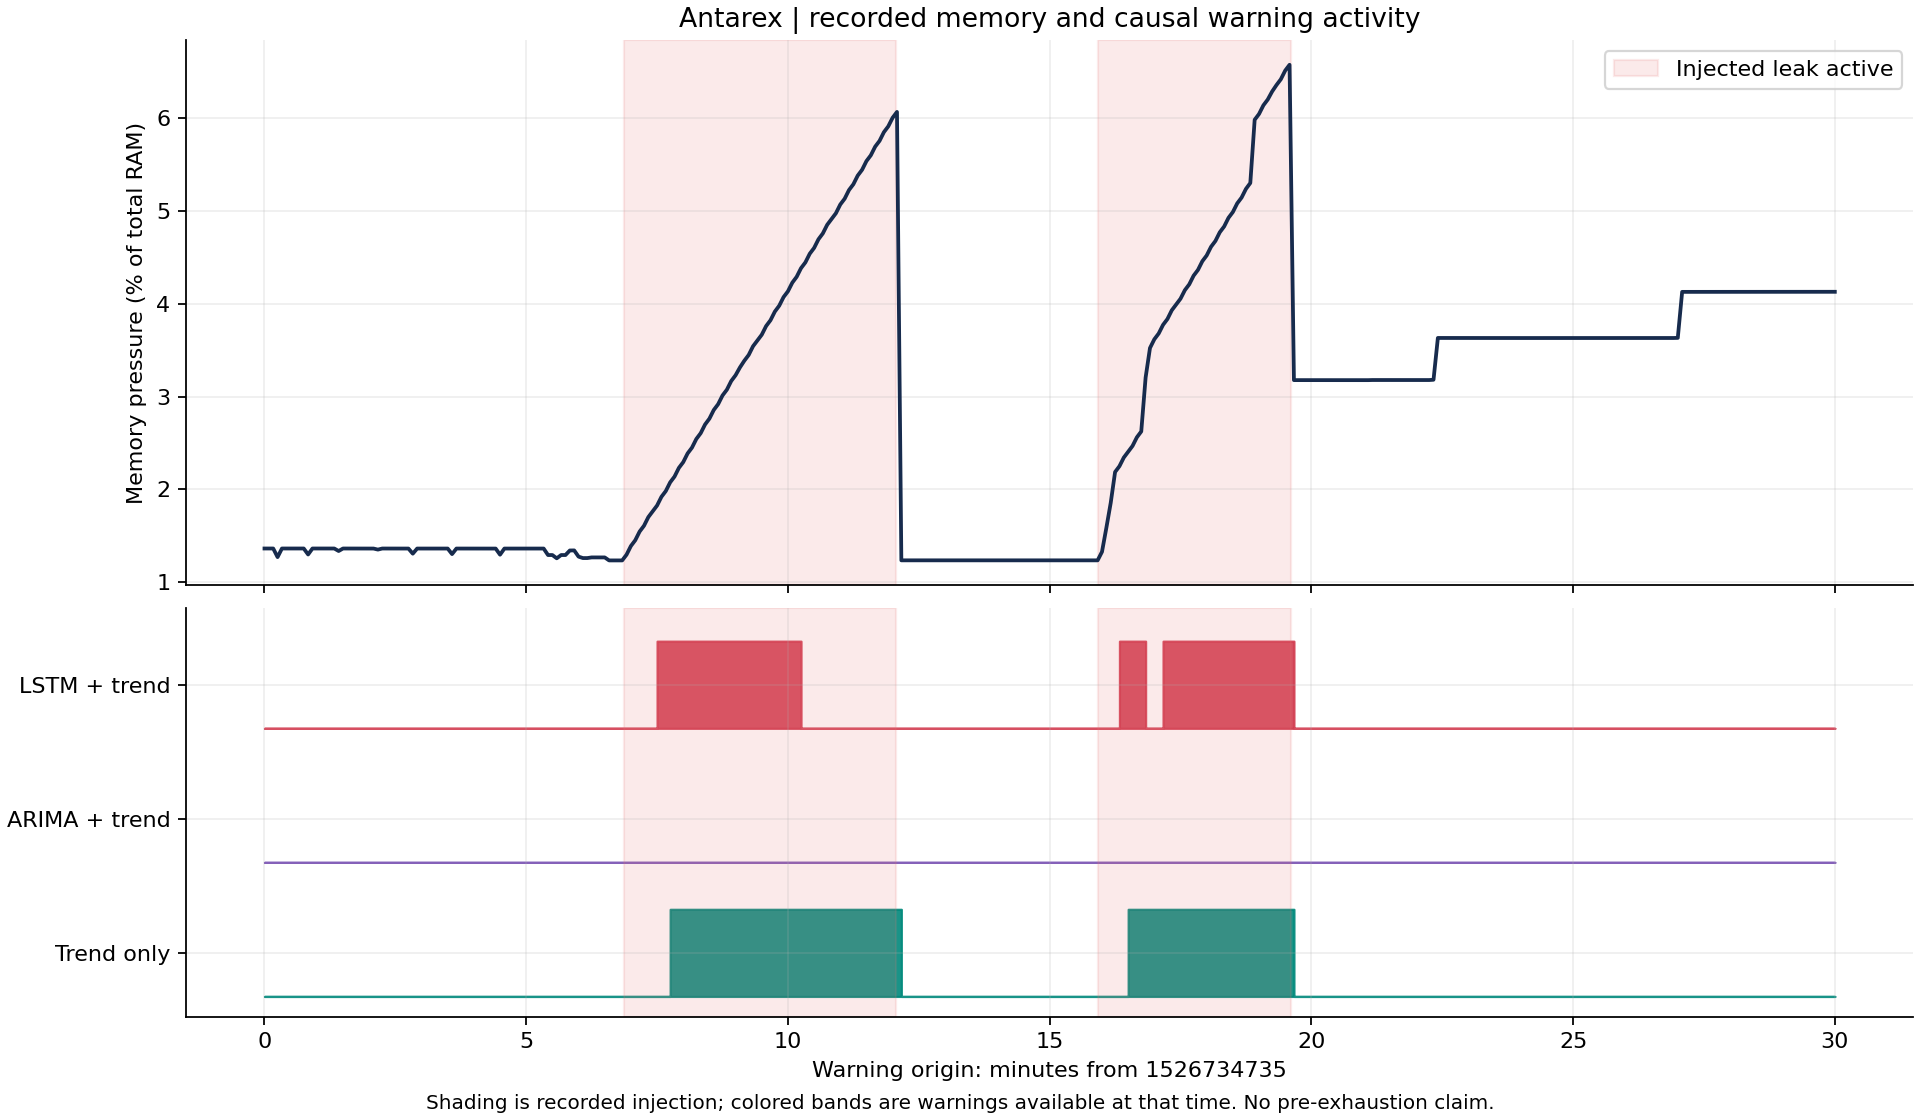

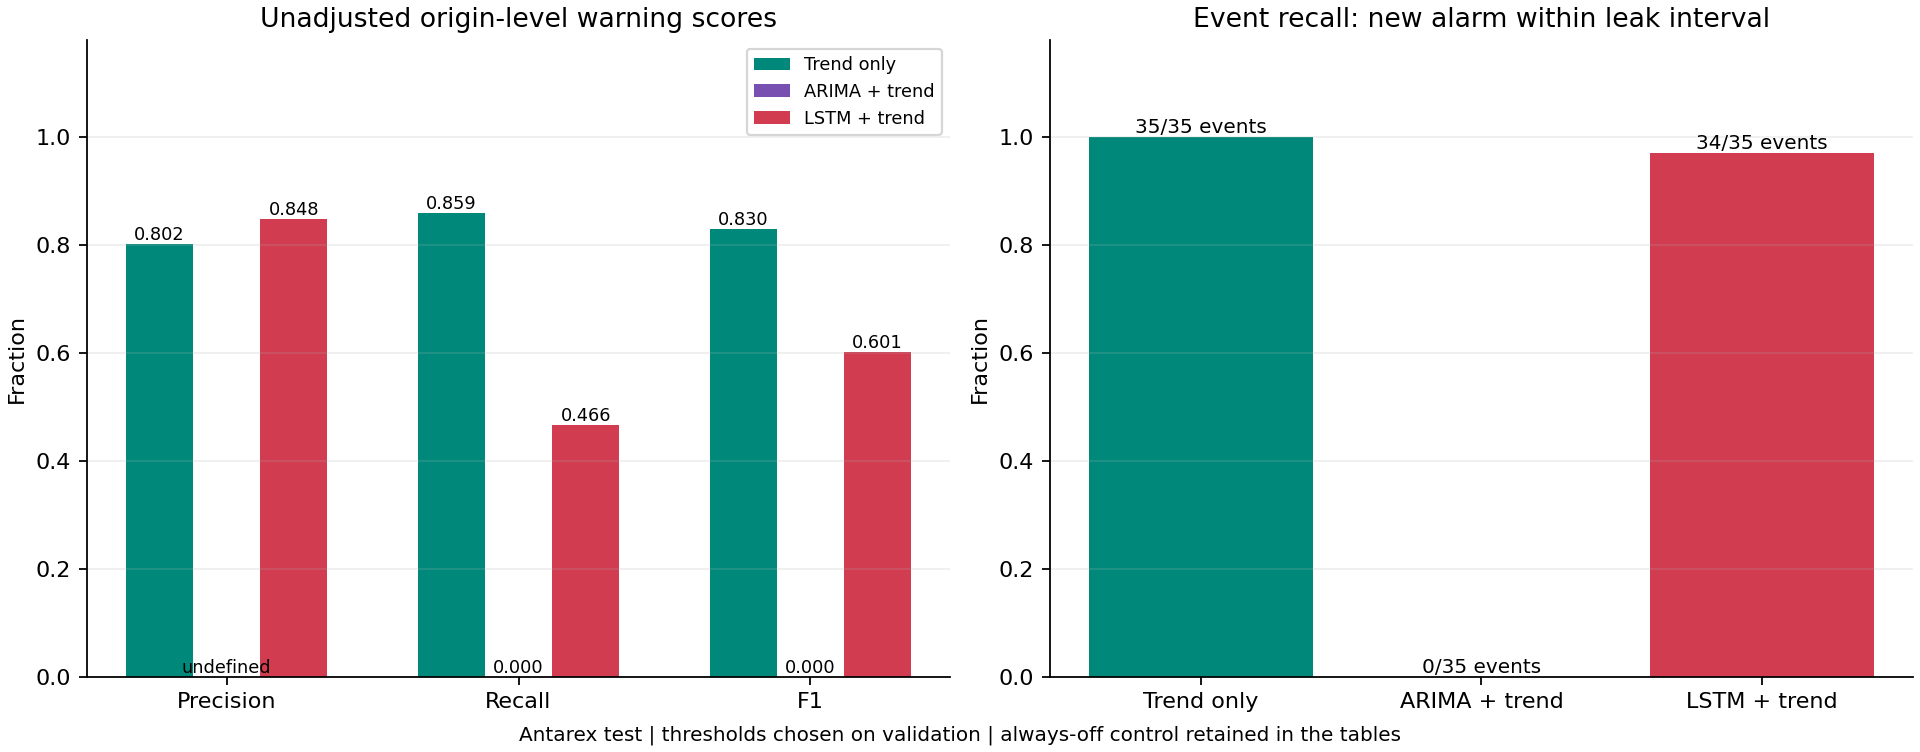

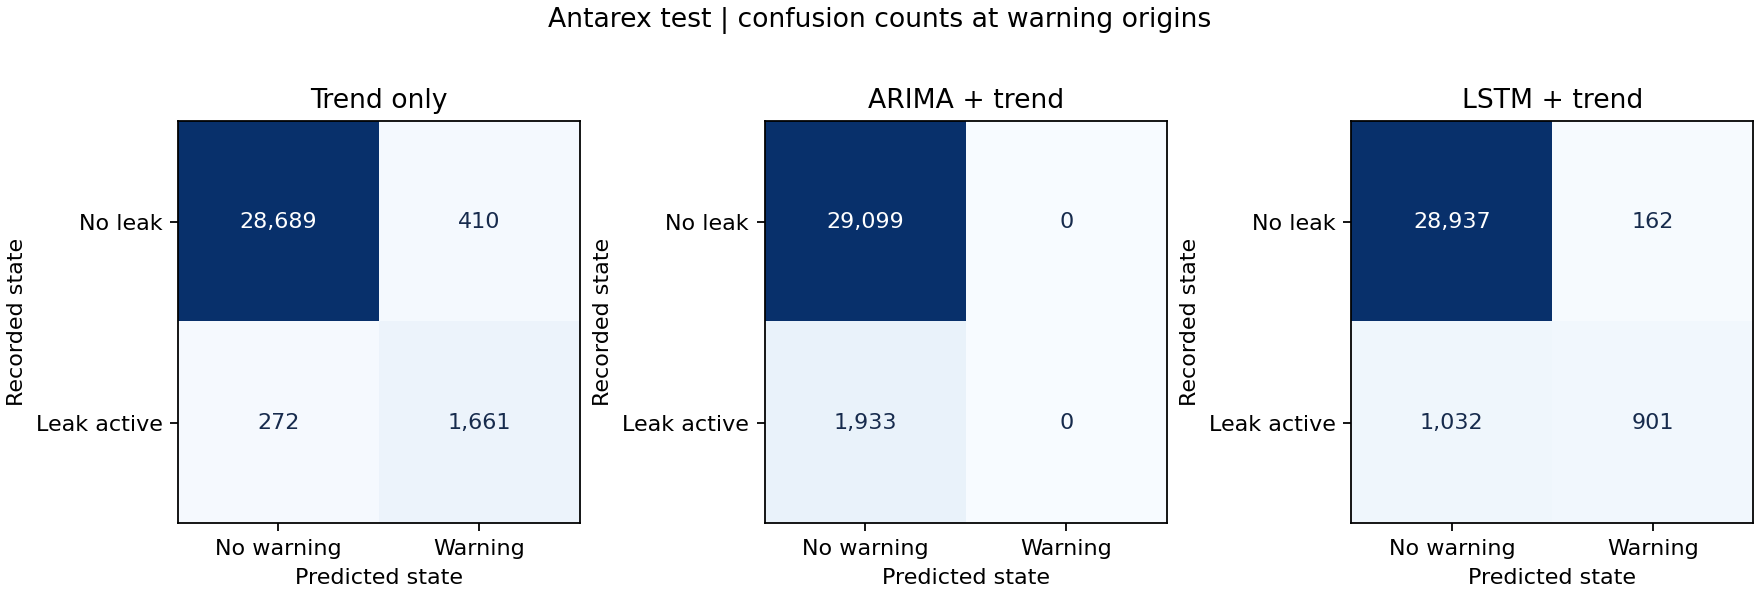

In [6]:
from PIL import Image
for relative in ['antarex_warning_timeline.png','antarex_warning_comparison.png','antarex_confusion_matrices.png']:
    with Image.open(OUTPUT/relative) as picture:
        display(picture)


## 7. Inspect Westermo descriptive alarm transfer
These use the frozen Antarex thresholds without fitting Westermo labels. Westermo's 12 observations span 330 seconds, its forecast horizon is 300 seconds and three qualifying samples span 60 seconds. Workloads and time scales differ. These alarm counts have no confirmed true/false interpretation.

In [7]:
display(pd.read_csv(OUTPUT/'westermo_descriptive_alarms.csv'))
print('Westermo leak precision/recall computed:',summary['westermo_leak_metrics_computed'])


dataset,split,method,eligible_origins,observed_hours,warning_origins,warning_fraction,alarm_starts,alarm_starts_per_observed_hour,leak_labels_available
westermo_1,test,trend_only,12891,107.425000,0,0.000000,0,0.000000,False
westermo_1,test,arima_growth,12891,107.425000,0,0.000000,0,0.000000,False
westermo_1,test,lstm_growth,12891,107.425000,0,0.000000,0,0.000000,False
westermo_1,test,always_off,12891,107.425000,0,0.000000,0,0.000000,False
westermo_2,test,trend_only,12745,106.208333,0,0.000000,0,0.000000,False
westermo_2,test,arima_growth,12745,106.208333,0,0.000000,0,0.000000,False
westermo_2,test,lstm_growth,12745,106.208333,0,0.000000,0,0.000000,False
westermo_2,test,always_off,12745,106.208333,0,0.000000,0,0.000000,False
westermo_3,test,trend_only,12891,107.425000,1,0.000078,1,0.009309,False
westermo_3,test,arima_growth,12891,107.425000,0,0.000000,0,0.000000,False


Westermo leak precision/recall computed: False


## 8. Verify saved outputs and download the result ZIP
This reconstructs warning decisions, validation selection, confusion counts, event outcomes and the plotted values. Download the ZIP only after `all_checks_passed: True`.

In [8]:
checks=verify_results(SOURCE,OUTPUT)
print(checks)
receipt=package_results(OUTPUT,RESULT_PACKAGE)
print(receipt)
if IN_COLAB:
    from google.colab import files
    files.download(str(RESULT_PACKAGE))


{'all_checks_passed': True, 'warning_decisions_recomputed': 402364, 'validation_selection_reproduced': True, 'test_confusion_counts_independently_reconstructed': True, 'event_outcomes_recomputed': True, 'westermo_labels_remain_unknown': True, 'selection_unchanged': True, 'point_adjustment_used': False}
{'file': 'review2_warning_results.zip', 'bytes': 6677468, 'sha256': '2247ef36633cef4e12c6c0338d23c9380e92e0e27247a5e965728df765f082a3', 'all_entry_hashes_verified': True}


## Save-and-review checkpoint
Save the download as **`review2_warning_results_colab.zip`** in **`C:/dhruv/VIT/Sem-5/OS/Research_Project/data/packages/`** and keep the executed notebook. Tell the assistant once it is saved so it can verify your Colab output.

The next separate stage is drafting the paper from the verified data, forecasting results and warning results. Full evaluation, ablations, multiple seeds, memory-exhaustion studies and deployment remain later work. This notebook alone does not complete the 75% milestone because the paper draft is still pending.


## Full frozen protocol

# Forecast-assisted leak-warning protocol — 9 September 2026

Defined before computing warning scores or selecting thresholds. This is the next experimental stage; it reuses the complete verified Colab forecasts and does not train or tune forecasting models. Earlier forecasting test errors and example plots have already been inspected. The warning thresholds will use validation labels only, with a selection record written before warning test scores are calculated. This is a pilot development split, not a new external test set.

## Question and scope

Does adding an existing 60-second-ahead memory forecast to a recent-growth rule help recognize ongoing injected leaks in Antarex? Compare a trend-only warning, an ARIMA-assisted warning and an LSTM-assisted warning. Keep an always-off control to expose class imbalance and undefined precision. These rules indicate leak-like growth; they do not prove root cause.

The Antarex pilot has no observed 80% memory-pressure crossing. The target is recognition after leak injection starts, not prediction of randomly scheduled onset, time before exhaustion, or crash prevention. Westermo is a separate, unlabeled alarm-transfer illustration, with no leak precision/recall or false-alarm claims.

## Fixed input and architecture

Use `review2_preprocessed_colab.zip` (SHA-256 `287ffaa139819f78f493e540e527c56ac0c240477034c76fa8b258b94d5e6bb2`) and `review2_lstm_results_colab.zip` (SHA-256 `42cd2d51f29a06d2f6a0912a8b787d343898b11ac3ac55c4b397264743c1a7bf`). Retain both nested packages unchanged in a new warning-input bundle with a manifest. Use all existing validation/test forecast origins; no labels or future actual values enter a score.

At origin t, let y(t) be memory pressure as a fraction of total RAM. Fit a least-squares slope using the most recent **12 observations including t**. Convert it into percentage points of total RAM per minute, g(t). Antarex's observations are 5 seconds apart, so this history spans 55 seconds. No regression significance or Mann–Kendall p-value is claimed.

For forecast method m, let f_m(t) be its saved, clipped prediction at t+h. Define q_m(t) = 100 × (f_m(t) − y(t)) / (h/60), also in percentage points per minute.

- Trend-only score: g(t).
- ARIMA-assisted score: min(g(t), q_ARIMA(t)).
- LSTM-assisted score: min(g(t), q_LSTM(t)).
- Always-off: never warn; no fitted threshold.

Thus an assisted score exceeds a positive threshold only when both recent observed growth and forecast growth exceed it. A warning is active starting at the **third consecutive eligible origin** whose score is at least the threshold; it stops immediately when the condition fails. Three Antarex samples span 10 seconds from the first qualifying sample to the first warning. There is no retrospective filling, cooldown, hysteresis or merging of alarms. Reset consecutive counts at split boundaries and gaps. Resetting does not use event labels.

Warning timestamps are forecast **origins**, not target timestamps. Labels are consulted only by calibration and evaluation. Existing forecast-window eligibility excludes split edges and gaps, so coverage and event exclusions must be reported.

## Threshold selection

Independently for each of the three scoring rules, evaluate the fixed grid **0.01, 0.025, 0.05, 0.1, 0.2, 0.4, 0.8, 1.6, 3.2** percentage points per minute, plus a disabled candidate. History length and consecutive count are fixed, not searched. Select the highest unadjusted, origin-level validation F1. Break ties by fewer false-positive origins and then the higher threshold (disabled sorts highest).

Save every candidate's validation confusion counts, precision, recall and F1. Freeze all selected thresholds, input hashes and settings before computing test warnings. No manual threshold changes or extra runs based on test results. This is supervised validation calibration, not an unsupervised end-to-end detector. The validation partition was also used for earlier forecast selection; this limits the independence of the development process.

## Antarex point metrics

Ground truth is whether injection is active at origin t, using the exact half-open interval [start, end). Report TP, FP, TN and FN; precision = TP/(TP+FP), recall = TP/(TP+FN), and F1 = 2TP/(2TP+FP+FN). Do not convert a whole leak interval into true positives when one warning occurs. Undefined ratios are saved as null/blank and shown as undefined; if leaks exist but no warnings occur, recall and F1 are zero and precision is undefined.

Also report warning fraction, non-leak false-positive fraction FP/(FP+TN), false-positive exposure minutes (FP × cadence / 60), and false alarm starts per observed non-leak hour. A new alarm starts when the warning changes from off to on, or starts after a coverage gap. A false alarm start occurs at a labeled non-leak origin. Non-leak exposure is the number of eligible non-leak origins × cadence; it includes other injected faults and is not synonymous with healthy operation. Coverage exposure is a discrete-cadence estimate, not full recording duration. Persistent alarms after a leak ends are penalized by false-positive origins even if no additional alarm starts occur.

## Event detection and delay

Evaluate each recorded leak separately. Include only events with complete eligible-origin coverage during the event and at least one covered sample immediately before onset. List all excluded events intersecting the scored interval and the reason (boundary or gap); ignore events entirely outside it.

Count an eligible event as detected only if a **new alarm starts inside [start, end)**. An alarm already active before onset does not earn a fresh event detection. Delay is the first such alarm-start timestamp minus the exact injection start. Report detected/eligible events, missed events, event recall, and median/90th-percentile delay **among detected events only**. Keep every event outcome in a table; missed events have no numerical delay. These sampled delays include up to one cadence of timing resolution and the rule's confirmation delay. Event recall and point precision are separate statistics and are not combined into an event F1.

## Westermo descriptive transfer

Apply the frozen Antarex thresholds unchanged to Westermo systems 1–3. Keep 12 past observations (spanning 330 seconds), a 300-second forecast horizon and three consecutive samples (60 seconds between first qualifying sample and warning). Express both scores in percentage points per minute as above. This is an exploratory transfer with different workloads and time scales, not a calibrated Westermo leak detector.

Report eligible origins, coverage hours, active-warning fraction, number of alarm starts and starts per observed hour. Labels remain unknown. Do not call an alarm false or infer a leak-free recording.

## Outputs and verification

Produce a self-contained CPU Colab notebook, validation candidate and frozen-threshold tables, origin-level warning timelines, confusion matrices, point metrics, event outcomes and delays, Westermo descriptive counts, provenance and a result ZIP with hashes. Plot the first 30 minutes of eligible Antarex test origins, not an interval selected for high performance. Show recorded injection separately from warning activity. Save plotting values and PNG/PDF figures.

Test causal indexing, current-versus-future label alignment, three-sample confirmation/gap resets, exact confusion counts including undefined precision, half-open event boundaries, boundary exclusions, no credit for pre-existing alarms, and selection invariance to test-value changes. Independently reconstruct saved confusion counts, event outcomes and warning states. Record offline execution time with its scope; this is not a measurement of end-to-end monitoring overhead.

## Methodological grounding and later work

Review 1 reference [13], [Jindal et al., Memory Leak Detection Algorithms in the Cloud-based Infrastructure (2021)](https://arxiv.org/abs/2106.08938), motivates using memory-growth trends as a comparator. This fixed slope/forecast conjunction is our pilot heuristic, not a reproduction of Precog. Review 1 reference [3], [Assi et al. (2022)](https://doi.org/10.22075/ijnaa.2022.26974.3505), grounds the earlier statistical-versus-LSTM forecasting comparison.

[Kim et al., Towards a Rigorous Evaluation of Time-Series Anomaly Detection, AAAI 2022](https://doi.org/10.1609/aaai.v36i7.20680) identifies inflated scores caused by point adjustment. Accordingly this evaluation keeps original point decisions and reports separate event outcomes without filling detected events. This protocol does not implement that paper's complete benchmark or claim to reproduce its results.

An autocorrelation-aware Mann–Kendall experiment, hybrid ARIMA–LSTM, broader threshold/architecture studies, multiple seeds, uncertainty estimates, memory-exhaustion recordings, and deployment measurements remain later work. Neither a high F1 nor a low forecasting error on this controlled pilot establishes production reliability. Paper drafting follows this experimental checkpoint and uses only completed results.
